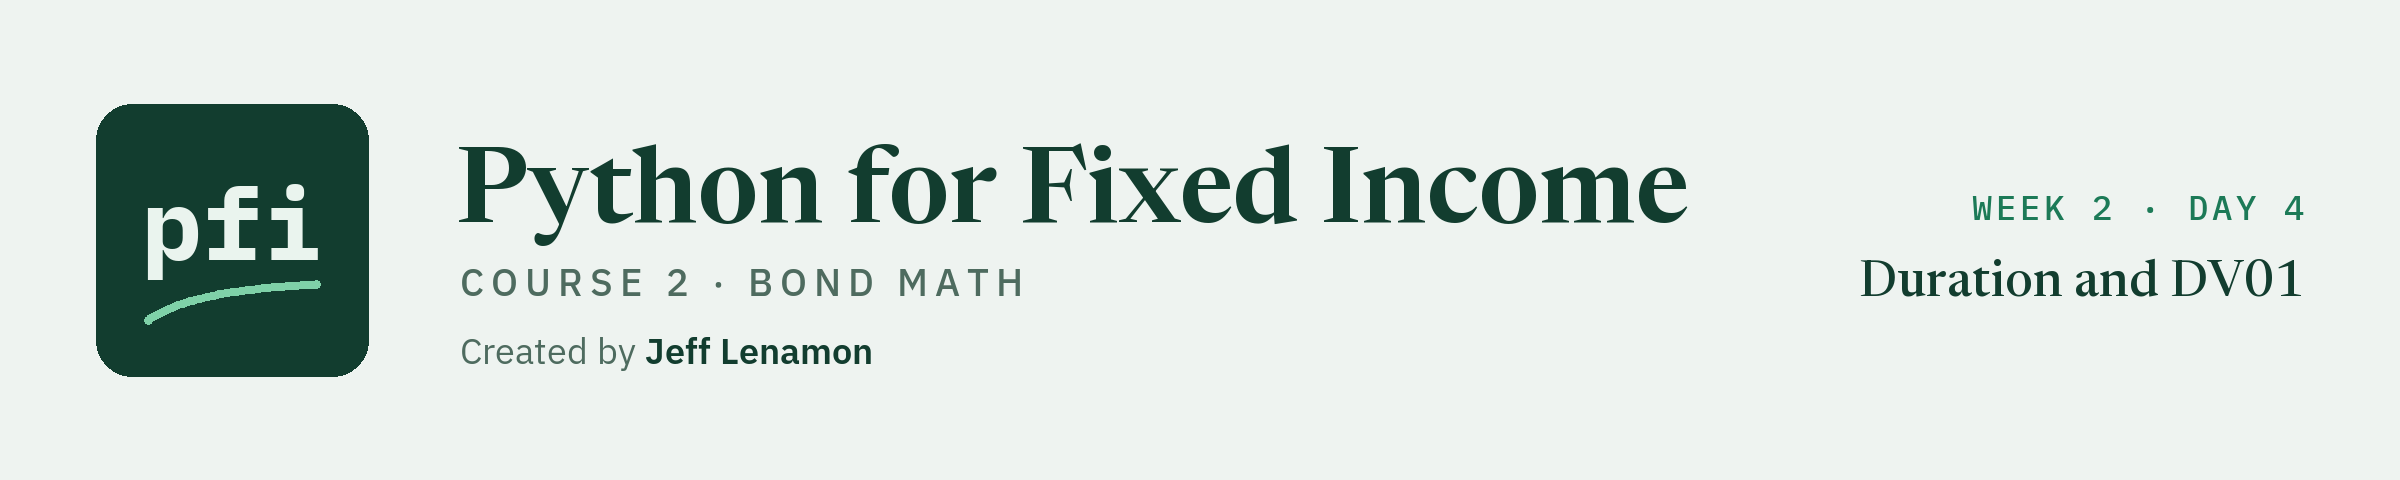

# Duration and DV01

Week 2, Day 4. How far a price moves when the yield moves: Macaulay and modified duration and DV01, per 100 and per position, tied to Excel's `DURATION` and `MDURATION`.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day4/09_duration_and_dv01.ipynb)

### The Desk Lead's Note

> We hold 5,000,000 Quorvane, 3,000,000 Dunmarrow, 4,000,000 Pellwick and 2,000,000 Halvering, settling Monday 30 November. If yields move one basis point, what does each position make or lose in dollars, and the book? Give `bondmath` duration and DV01, tied to Excel. Last, September's holdings file has a `duration` column that does not say which duration it is: find out.

A basis point (bp) is a hundredth of a percent, as in notebook 03.
The issuers and positions are invented; every statement describes the data.

**Notebook 08 priced these bonds on 30 November; today asks how far each price moves.**

### Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 08 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(9)

Work folder pfi_course2_09_k4w7q2xr: 3 data files, the module as notebook 08 left it, 8 commits, tagged week1


### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................                                                  [100%]
23 passed in 0.50s



### Imports and the Four Positions

Q. Which bonds, and how much of each?

In [3]:
import importlib
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
import bondmath

In [4]:
# the four week 1 bonds at their issue yields; par_held is the face held, in dollars
bonds = pd.DataFrame({
    'cusip': ['99001BZA7', '99002CZA4', '99003DZA1', '99004EZA8'],
    'issuer': ['Quorvane Energy', 'Dunmarrow Rail', 'Pellwick Paper', 'Halvering Foods'],
    'coupon_pct': [5.25, 6.125, 4.75, 7.5],
    'maturity': [date(2031, 9, 30), date(2033, 9, 30), date(2029, 9, 30), date(2036, 9, 30)],
    'yield_pct': [5.4, 6.125, 4.6, 7.7],
    'par_held': [5_000_000, 3_000_000, 4_000_000, 2_000_000],
})
settlement = date(2026, 11, 30)
quorvane_maturity = date(2031, 9, 30)
maturities, coupons, yields = bonds['maturity'], bonds['coupon_pct'], bonds['yield_pct']

In [5]:
# Excel's answers: the week2 rows are these bonds and four more, settled 30 November
reference = pd.read_csv('bondmath_excel_reference.csv')
week2 = reference[reference['group'] == 'week2'].set_index('case_id')
print(len(reference), 'reference rows,', len(week2), 'of them in week2')

306 reference rows, 8 of them in week2


### The Price Every Sensitivity Starts From

Q. What is each bond worth on 30 November, per 100? Notebook 08's `dirty_price`.

In [6]:
bonds['dirty'] = [bondmath.dirty_price(settlement, m, c, y)
                  for m, c, y in zip(maturities, coupons, yields)]
bonds[['issuer', 'par_held', 'dirty']].round(6)

,issuer,par_held,dirty
0,Quorvane Energy,5000000,100.236551
1,Dunmarrow Rail,3000000,101.010586
2,Pellwick Paper,4000000,101.179914
3,Halvering Foods,2000000,99.872491


Quorvane's 100.236551 is notebook 08's 99.361551 quote plus 0.875 of accrued.

**Every sensitivity today is measured on the dirty price: that is what the position is worth.**

## 9.1 Macaulay Duration: the Average Time of the Cash Flows

Quorvane matures on 30 September 2031, but that is only the date of its last payment.
Nine coupons come before it.

### Quorvane's Ten Payments

Q. When does each payment arrive, and what share of the price is it?

In [7]:
# w: the part of a period left until the next coupon (notebook 08)
days_accrued, days_in_period, days_to_next = bondmath.coupon_period_days(settlement,
                                                                         quorvane_maturity)
w = days_to_next / days_in_period
rows = []
for k in range(10):
    # a coupon of 5.25 / 2, and the face with the last one, w + k periods away
    cash_flow = 5.25 / 2 + (100 if k == 9 else 0)
    rows.append({'time_years': (w + k) / 2, 'pv': cash_flow / (1 + 5.40 / 100 / 2) ** (w + k)})
flows = pd.DataFrame(rows)

In [8]:
# each payment's share of the price: its present value over their sum, the dirty price
flows['weight'] = flows['pv'] / flows['pv'].sum()
flows.style.format('{:.6f}').background_gradient(subset=['weight'], cmap='Greens')

,time_years,pv,weight
0,0.333333,2.578788,0.025727
1,0.833333,2.510991,0.025051
2,1.333333,2.444977,0.024392
3,1.833333,2.380698,0.023751
4,2.333333,2.318109,0.023126
5,2.833333,2.257166,0.022518
6,3.333333,2.197825,0.021926
7,3.833333,2.140043,0.021350
8,4.333333,2.083781,0.020789
9,4.833333,79.324172,0.791370


The weights add up to 1; the last payment, coupon plus face, carries 0.791 of the value.

**Predict 1**

Q. The last payment is 4.833333 years away and carries 79 percent of the value; nine coupons come earlier. What is the value-weighted average time of the ten payments, in years? Write down a number.

### Weight Each Time

In [9]:
# each time multiplied by its weight, then added up
macaulay_by_hand = (flows['time_years'] * flows['weight']).sum()
print(f'Weighted average time: {macaulay_by_hand:.6f} years')
print(f"Last payment:          {flows['time_years'].iloc[-1]:.6f} years")

Weighted average time: 4.293248 years
Last payment:          4.833333 years


![Quorvane's ten payments as weights on a ruler from 0 to 5 years: nine small coupons of 2.57 down to 2.08 percent of the price, and the coupon and face, 79.14 percent, at 4.83 years. The ruler balances at 4.29 years. Time t = (w + k) / 2, weight = PV / dirty price, and the PVs add up to 100.236551](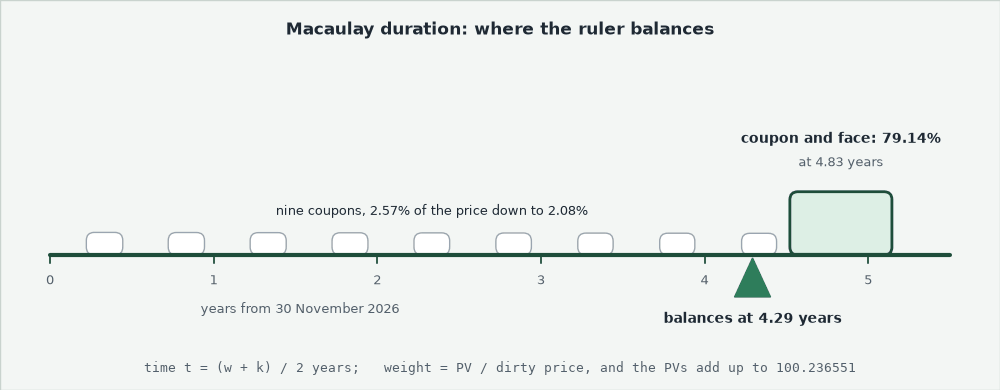)

That average is **Macaulay duration**: each payment's time, weighted by its present value over their sum, the dirty price.
The nine coupons pull the balance point 0.54 years in from the last payment.

**Excel side by side.** A blank sheet with k = 0 to 9 typed in A2:A11.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Times, cash flows, present values, B2 to D2 filled down</td><td align="left"><code>flows</code></td><td align="left"><code>=(120/180+A2)/2</code>, <code>=IF(A2=9,5.25/2+100,5.25/2)</code>, <code>=C2/(1+5.4/100/2)^(120/180+A2)</code></td><td align="left">0.333333 to 4.833333 years</td></tr>
<tr><td align="left">The weighted average time</td><td align="left"><code>macaulay_by_hand</code></td><td align="left"><code>=SUMPRODUCT(B2:B11,D2:D11)/SUM(D2:D11)</code></td><td align="left">4.293247884617172</td></tr>
</table>
<br clear="left">

> STORY: In 1938 Frederick R. Macaulay, writing for the National Bureau of Economic Research, argued that maturity, the date of the last payment, is a poor measure of how long a loan really lasts: "'Duration' is a reality of which 'maturity' is only one factor." He weighted each payment's time by its present value over their sum, "the price paid for the bond": the cell above. Source: NBER, https://www.nber.org/books-and-chapters/some-theoretical-problems-suggested-movements-interest-rates-bond-yields-and-stock-prices-united/concept-long-term-interest-rates

**Macaulay duration is where the value sits in time: 4.29 years, not the 4.83 to the last payment.**

## 9.2 Test First: `macaulay_duration`

![Four steps in a loop. 1, write the test, which checks Excel's DURATION before the function exists. 2, run pytest: 1 failed, 23 passed, an AttributeError. 3, write the function, macaulay_duration, docstring first. 4, run pytest again: 24 passed; it failed first, so it counts. Then the next function](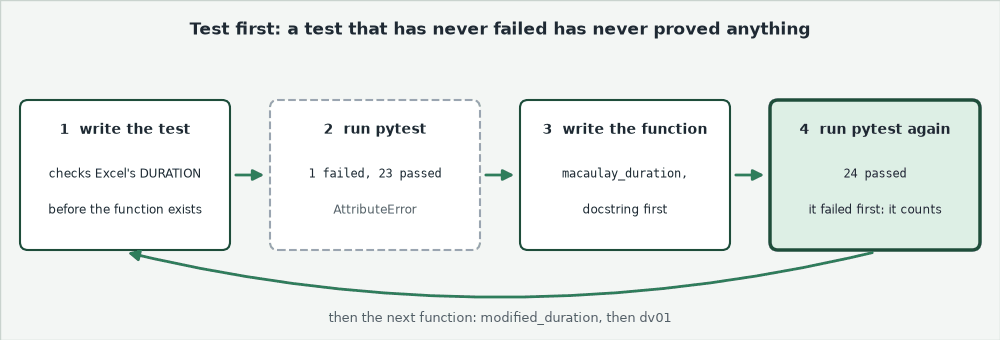)

Every function so far was written first and tested after.
Today the test comes first: run before its function exists, it must fail, and a test that has never failed has never proved anything.

### The Test

`macaulay_duration` will take `price`'s six arguments.
The test holds it to Excel's `duration` column on all 306 reference rows; `bond_inputs` (notebook 07) turns a row into the six arguments.

In [10]:
%%writefile -a test_bondmath.py


def test_macaulay_matches_excel_duration():
    for row in REFERENCE:
        result = bondmath.macaulay_duration(*bond_inputs(row))
        assert result == pytest.approx(float(row["duration"]), abs=1e-6), row["case_id"]

Appending to test_bondmath.py


### Run It Before the Function Exists

In [11]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................F                                                 [100%]
================================== FAILURES ===================================
____________________ test_macaulay_matches_excel_duration _____________________

    def test_macaulay_matches_excel_duration():
        for row in REFERENCE:
>           result = bondmath.macaulay_duration(*bond_inputs(row))
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^
E           AttributeError: module 'bondmath' has no attribute 'macaulay_duration'

test_bondmath.py:282: AttributeError
=========================== short test summary info ===========================
FAILED test_bondmath.py::test_macaulay_matches_excel_duration - AttributeError: module 'bondmath' has no attribute 'macaulay_duration'
1 failed, 23 passed in 0.50s



The `E` line says why: `bondmath` has no `macaulay_duration` yet.
That is the failure we wanted.

### Write the Function

The docstring states the units (years), the convention (t = (w + k) / f, weighted by present value) and `DURATION` with its `/100`.
The loop is 9.1's, with the coupon, yield and frequency as arguments.
With one payment left it runs once and returns DSC / E / f, as Excel does.

In [12]:
%%writefile -a bondmath.py


def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Macaulay duration in years: the present-value weighted average time of the cash flows.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, weighted_time = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow, its time in years, and its present value
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        pv = cash_flow / (1 + period_yield) ** (w + k)
        total_pv += pv
        weighted_time += time_years * pv
    # the weighted average time
    return weighted_time / total_pv

Appending to bondmath.py


### Run It Again

In [13]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

........................                                                 [100%]
24 passed in 0.50s



The test that failed now passes, on all 306 rows.

### Four Bonds Against DURATION

In [14]:
importlib.reload(bondmath)
bonds['macaulay'] = [bondmath.macaulay_duration(settlement, m, c, y)
                     for m, c, y in zip(maturities, coupons, yields)]
bonds['excel'] = week2.loc[bonds['cusip'], 'duration'].to_numpy()
assert (bonds['macaulay'] - bonds['excel']).abs().max() < 1e-6
# 365.25 days to a year, as in Course 1
bonds['years_to_maturity'] = [(m - settlement).days / 365.25 for m in maturities]
bonds[['issuer', 'years_to_maturity', 'macaulay', 'excel']].round(6)

,issuer,years_to_maturity,macaulay,excel
0,Quorvane Energy,4.832307,4.293248,4.293248
1,Dunmarrow Rail,6.833676,5.629619,5.629619
2,Pellwick Paper,2.833676,2.665045,2.665045
3,Halvering Foods,9.834360,7.020017,7.020017


### Duration Beside Maturity

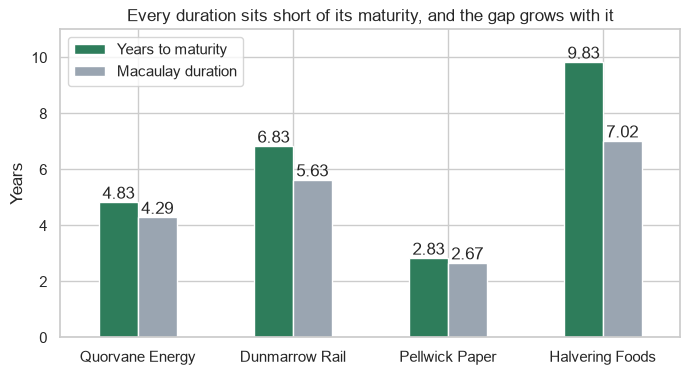

In [15]:
to_plot = bonds.set_index('issuer')[['years_to_maturity', 'macaulay']].rename(
    columns={'years_to_maturity': 'Years to maturity', 'macaulay': 'Macaulay duration'})
fig, ax = plt.subplots(figsize=(8, 4))
# ax= draws pandas' bars on our axes, as seaborn's ax= does
to_plot.plot.bar(rot=0, ax=ax, xlabel='')
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f')
ax.set_ylim(0, 11)
ax.set_title('Every duration sits short of its maturity, and the gap grows with it')
ax.set_ylabel('Years')
plt.show()

The gap runs from 0.17 years for Pellwick to 2.81 for Halvering, whose 7.5 percent coupon brings value forward.

**Predict 2**

Q. Give Quorvane's dates a coupon of 0: a zero, one payment at maturity. Move Quorvane and the zero from 5.40 to 10 percent. Their Macaulay durations:

A) both fall
B) Quorvane's falls, and the zero's does not move
C) neither moves

### Both at 10 Percent

In [16]:
for yield_pct in (5.40, 10.0):
    coupon_bond = bondmath.macaulay_duration(settlement, quorvane_maturity, 5.25, yield_pct)
    zero = bondmath.macaulay_duration(settlement, quorvane_maturity, 0.0, yield_pct)
    print(f'At {yield_pct:>5.2f} percent: Quorvane {coupon_bond:.6f}, the zero {zero:.6f} years')

At  5.40 percent: Quorvane 4.293248, the zero 4.833333 years
At 10.00 percent: Quorvane 4.225090, the zero 4.833333 years


B: a higher yield shrinks the far payments most, so Quorvane's weight moves to the early coupons.
The zero has one payment, so its duration is its maturity at any yield; a coupon bond's is shorter.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Quorvane</td><td align="left"><code>bondmath.macaulay_duration(settlement, quorvane_maturity, 5.25, 5.40)</code></td><td align="left"><code>=DURATION(DATE(2026,11,30),DATE(2031,9,30),5.25/100,5.4/100,2,0)</code></td><td align="left">4.293247884617173</td></tr>
<tr><td align="left">The zero</td><td align="left"><code>bondmath.macaulay_duration(settlement, quorvane_maturity, 0.0, 5.40)</code></td><td align="left"><code>=DURATION(DATE(2026,11,30),DATE(2031,9,30),0,5.4/100,2,0)</code></td><td align="left">4.833333333333333</td></tr>
</table>
<br clear="left">

**`macaulay_duration` is Excel's `DURATION` on all 306 rows, and its test failed first, so it proved something.**

## 9.3 Modified Duration: Price Sensitivity

Macaulay duration is a time; the desk asks how far the price moves.
Divide it by one plus the period yield and you have **modified duration**, the price's slope as a share of the price:

modified duration = Macaulay duration / (1 + y / 2), with y the yield as a decimal and 2 coupons a year.

The price moves about modified duration percent for 100 bp, and modified duration x 0.0001, as a share, for 1 bp.

### Divide by One Plus the Period Yield

In [17]:
modified_by_hand = macaulay_by_hand / (1 + 5.40 / 100 / 2)
print(f'Modified duration: {modified_by_hand:.6f}')

Modified duration: 4.180378


### One Basis Point, Repriced

Q. Reprice Quorvane 1 bp higher: does the dirty price fall by modified duration x 0.0001?

In [18]:
dirty_now = bondmath.dirty_price(settlement, quorvane_maturity, 5.25, 5.40)
# 5.41 percent: the yield 1 bp, 0.01 percent, higher
dirty_up = bondmath.dirty_price(settlement, quorvane_maturity, 5.25, 5.41)
print(f'Repriced:          {(dirty_up / dirty_now - 1) * 100:.8f} percent')
print(f'Modified duration: {-modified_by_hand * 0.0001 * 100:.8f} percent')

Repriced:          -0.04179333 percent
Modified duration: -0.04180378 percent


The straight line and the reprice agree to 1e-05 percent of the price.
How far the line misses for 100 bp is notebook 10's question.

### Test and Function

The test reads Excel's `mduration` column.
The function divides `macaulay_duration` by one plus the period yield rather than repeat the loop.

In [19]:
%%writefile -a test_bondmath.py


def test_modified_matches_excel_mduration():
    for row in REFERENCE:
        result = bondmath.modified_duration(*bond_inputs(row))
        assert result == pytest.approx(float(row["mduration"]), abs=1e-6), row["case_id"]

Appending to test_bondmath.py


In [20]:
%%writefile -a bondmath.py


def modified_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Modified duration in years: the percent price change for a 1-point (100 bp) change in yield.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: Macaulay duration / (1 + y / frequency), with y = yield_pct / 100.
    Excel: =MDURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # divide Macaulay duration by one plus the period yield
    period_yield = yield_pct / 100 / frequency
    return macaulay_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis) / (1 + period_yield)

Appending to bondmath.py


In [21]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........................                                                [100%]
25 passed in 0.50s



### Four Bonds Against MDURATION

In [22]:
importlib.reload(bondmath)
bonds['modified'] = [bondmath.modified_duration(settlement, m, c, y)
                     for m, c, y in zip(maturities, coupons, yields)]
bonds['excel'] = week2.loc[bonds['cusip'], 'mduration'].to_numpy()
assert (bonds['modified'] - bonds['excel']).abs().max() < 1e-6
bonds[['issuer', 'yield_pct', 'macaulay', 'modified', 'excel']].round(6)

,issuer,yield_pct,macaulay,modified,excel
0,Quorvane Energy,5.400,4.293248,4.180378,4.180378
1,Dunmarrow Rail,6.125,5.629619,5.462335,5.462335
2,Pellwick Paper,4.600,2.665045,2.605127,2.605127
3,Halvering Foods,7.700,7.020017,6.759766,6.759766


Each is its Macaulay duration over 1 + y / 2: 1.023 for Pellwick up to 1.0385 for Halvering.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Modified duration</td><td align="left"><code>bondmath.modified_duration(settlement, quorvane_maturity, 5.25, 5.40)</code></td><td align="left"><code>=MDURATION(DATE(2026,11,30),DATE(2031,9,30),5.25/100,5.4/100,2,0)</code></td><td align="left">4.180377687066382</td></tr>
<tr><td align="left">The division</td><td align="left"><code>modified_by_hand</code></td><td align="left"><code>=DURATION(DATE(2026,11,30),DATE(2031,9,30),5.25/100,5.4/100,2,0)/(1+5.4/100/2)</code></td><td align="left">4.180377687066382</td></tr>
</table>
<br clear="left">

**Quorvane's price moves about 0.0418 percent for each basis point.**

## 9.4 DV01 per 100 and per Position

A trader talks in price points and a portfolio manager in dollars.
**DV01**, the dollar value of a basis point, is modified duration x dirty price x 0.0001: price points per 100 of face that a long position gains when the yield falls 1 bp.
A position's DV01 in dollars is DV01 x par held / 100.

### Test and Function

Excel has no DV01 function: the reference file's `dv01` column is `MDURATION` x (`PRICE` + accrued) / 10000, so the test is tighter, 1e-8 per 100.

In [23]:
%%writefile -a test_bondmath.py


def test_dv01_matches_excel_formula():
    for row in REFERENCE:
        result = bondmath.dv01(*bond_inputs(row))
        # Excel: MDURATION x (PRICE + accrued) / 10000
        assert result == pytest.approx(float(row["dv01"]), abs=1e-8), row["case_id"]

Appending to test_bondmath.py


In [24]:
%%writefile -a bondmath.py


def dv01(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
         basis: str = "30/360") -> float:
    """DV01: price points per 100 of face for a 1 basis point fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result is in price points per 100 of face per bp.
    Convention: modified duration x dirty price x 0.0001. Position DV01 in dollars = dv01 x par / 100.
    Excel: =MDURATION(...)*(PRICE(...)+accrued)/10000
    """
    # modified duration times the dirty price, for one basis point (0.0001 as a decimal)
    duration_years = modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    return duration_years * full_price * 0.0001

Appending to bondmath.py


In [25]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........................                                               [100%]
26 passed in 0.50s



### DV01 per 100

In [26]:
importlib.reload(bondmath)
bonds['dv01'] = [bondmath.dv01(settlement, m, c, y)
                  for m, c, y in zip(maturities, coupons, yields)]
bonds['excel'] = week2.loc[bonds['cusip'], 'dv01'].to_numpy()
assert (bonds['dv01'] - bonds['excel']).abs().max() < 1e-8
bonds[['issuer', 'par_held', 'dv01', 'excel']].round(6)

,issuer,par_held,dv01,excel
0,Quorvane Energy,5000000,0.041903,0.041903
1,Dunmarrow Rail,3000000,0.055175,0.055175
2,Pellwick Paper,4000000,0.026359,0.026359
3,Halvering Foods,2000000,0.067511,0.067511


Halvering, the longest bond, moves most per 100 of face.

**Predict 3**

Q. Which position carries the most dollars per basis point?

A) Halvering, the largest DV01 per 100
B) Quorvane, the largest position
C) Dunmarrow, second on both

### Every Position, and the Book

In [27]:
# price points per 100 of face, scaled to the face held: dollars per bp
bonds['position_dv01'] = bonds['dv01'] * bonds['par_held'] / 100
print(f"Book DV01: {bonds['position_dv01'].sum():,.2f} dollars per basis point")
bonds[['issuer', 'position_dv01']].round(2)

Book DV01: 6,154.97 dollars per basis point


,issuer,position_dv01
0,Quorvane Energy,2095.13
1,Dunmarrow Rail,1655.26
2,Pellwick Paper,1054.35
3,Halvering Foods,1350.23


![Quorvane, 5,000,000 of face. Macaulay duration 4.293248 years, divided by 1 + 5.4 / 100 / 2 = 1.027, is modified duration 4.180378 years; times the dirty price 100.236551 times 0.0001 is DV01 0.041903 price points per 100 per bp; times 5,000,000 / 100 is the position DV01, 2,095.13 dollars per bp](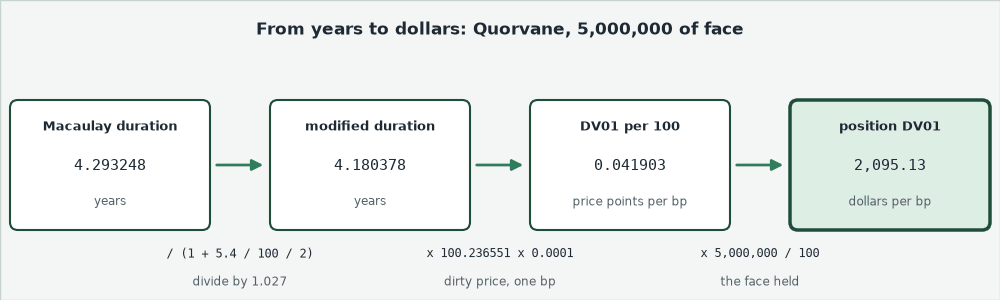)

B: Quorvane's position carries the most; a position's risk is its risk per 100 times its size.
The picture follows its 2,095.13 dollars back to 9.1's 4.29 years.
DV01 adds across positions because it is in dollars; duration does not.

### Per 100 and Per Position

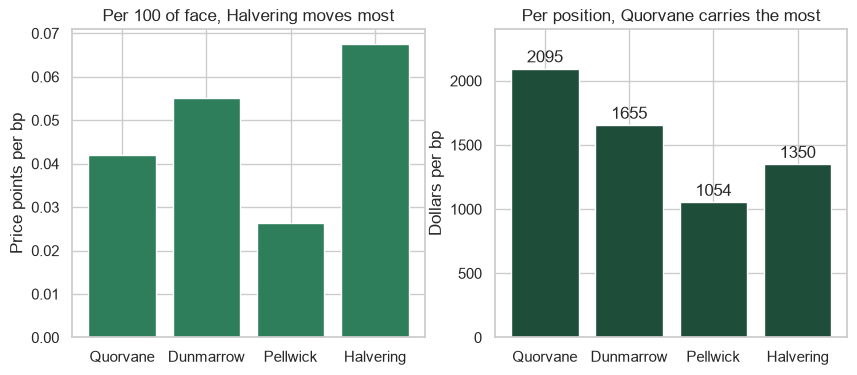

In [28]:
# the first word of each issuer, so four labels fit under each panel
names = bonds['issuer'].str.split().str[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(names, bonds['dv01'])
axes[0].set_title('Per 100 of face, Halvering moves most')
axes[0].set_ylabel('Price points per bp')
bars = axes[1].bar(names, bonds['position_dv01'], color='#1E4D3A')
axes[1].bar_label(bars, fmt='%.0f', padding=2)
axes[1].set_ylim(0, 2400)
axes[1].set_title('Per position, Quorvane carries the most')
axes[1].set_ylabel('Dollars per bp')
plt.show()

**Excel side by side.** Excel has no DV01 function; build it from three, for Quorvane.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Clean price, B1</td><td align="left"><code>bondmath.price(settlement, quorvane_maturity, 5.25, 5.40)</code></td><td align="left"><code>=PRICE(DATE(2026,11,30),DATE(2031,9,30),5.25/100,5.4/100,100,2,0)</code></td><td align="left">99.36155142589135</td></tr>
<tr><td align="left">Accrued, B2</td><td align="left"><code>bondmath.accrued_interest(settlement, quorvane_maturity, 5.25)</code></td><td align="left"><code>=100*5.25/100/2*COUPDAYBS(DATE(2026,11,30),DATE(2031,9,30),2,0)/COUPDAYS(DATE(2026,11,30),DATE(2031,9,30),2,0)</code></td><td align="left">0.875</td></tr>
<tr><td align="left">Modified duration, B4</td><td align="left"><code>bonds['modified']</code></td><td align="left"><code>=MDURATION(DATE(2026,11,30),DATE(2031,9,30),5.25/100,5.4/100,2,0)</code></td><td align="left">4.180377687066382</td></tr>
<tr><td align="left">DV01 per 100, B5</td><td align="left"><code>bonds['dv01']</code></td><td align="left"><code>=B4*(B1+B2)/10000</code></td><td align="left">0.04190266430092781</td></tr>
<tr><td align="left">Position DV01, B11</td><td align="left"><code>bonds['position_dv01']</code></td><td align="left"><code>=B5*5000000/100</code></td><td align="left">2095.1332150463904</td></tr>
</table>
<br clear="left">

**The book moves 6,154.97 dollars for each basis point, and Quorvane, not Halvering, carries the most.**

## 9.5 Checking DV01 by Bumping the Yield

![A price-yield curve drawn bent far more than it is. Points at yields 5.39 and 5.41, clean prices 99.403465 and 99.319659, joined by a dashed chord, the bump: half the drop is 0.041903 per 100. Beside it the tangent at 5.40, the formula: dv01 = 0.041903 per 100](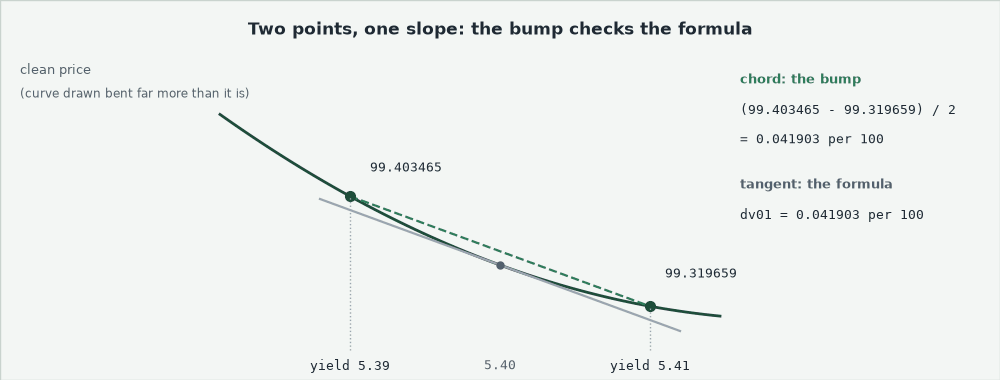)

`dv01` is a slope at 5.40.
A check that needs no formula: price the bond 1 bp lower and 1 bp higher and take half the difference, the slope of the chord between them.

### Price It 1 bp Either Side

In [29]:
bumps = bonds[['issuer', 'dv01']].copy()
# clean prices 0.01 percent either side of each yield, half the difference
bumps['bump'] = [(bondmath.price(settlement, m, c, y - 0.01)
                  - bondmath.price(settlement, m, c, y + 0.01)) / 2
                 for m, c, y in zip(maturities, coupons, yields)]
bumps['gap'] = bumps['bump'] - bumps['dv01']
bumps

,issuer,dv01,bump,gap
0,Quorvane Energy,0.041903,0.041903,1.944215e-09
1,Dunmarrow Rail,0.055175,0.055175,4.503757e-09
2,Pellwick Paper,0.026359,0.026359,5.215240e-10
3,Halvering Foods,0.067511,0.067511,9.715958e-09


The bump uses clean prices and `dv01` the dirty price; accrued depends on the dates, not the yield, so it cancels in the difference.

### The Fourth Test

The test bumps with Excel's own prices, the `price_down_1bp` and `price_up_1bp` columns.
In the final period `PRICE` is simple interest (notebook 08's 8.5), so there the bump measures another formula.
The comprehension's `if` keeps the other rows, as notebook 08's final-period test picked its rows.

In [30]:
%%writefile -a test_bondmath.py


def test_dv01_close_to_bump():
    # the final period is simple interest, so the bump measures another formula there
    rows = [row for row in REFERENCE if row["coupnum"] != "1"]
    for row in rows:
        # Excel's PRICE 1 bp lower and 1 bp higher, half the difference
        bump = (float(row["price_down_1bp"]) - float(row["price_up_1bp"])) / 2
        assert bondmath.dv01(*bond_inputs(row)) == pytest.approx(bump, abs=1e-6), row["case_id"]

Appending to test_bondmath.py


In [31]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........................                                              [100%]
27 passed in 0.50s



**Excel side by side.** The bump with two `PRICE` cells.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">1 bp lower, B8</td><td align="left"><code>bondmath.price(settlement, quorvane_maturity, 5.25, 5.39)</code></td><td align="left"><code>=PRICE(DATE(2026,11,30),DATE(2031,9,30),5.25/100,(5.4-0.01)/100,100,2,0)</code></td><td align="left">99.40346456111178</td></tr>
<tr><td align="left">1 bp higher, B9</td><td align="left"><code>bondmath.price(settlement, quorvane_maturity, 5.25, 5.41)</code></td><td align="left"><code>=PRICE(DATE(2026,11,30),DATE(2031,9,30),5.25/100,(5.4+0.01)/100,100,2,0)</code></td><td align="left">99.31965922862149</td></tr>
<tr><td align="left">Half the difference, B10</td><td align="left"><code>bumps['bump']</code></td><td align="left"><code>=(B8-B9)/2</code></td><td align="left">0.04190266624514294</td></tr>
</table>
<br clear="left">

B10 sits 1.9e-09 from B5, the formula.

**Two routes, one number: the formula and the bump agree to 1e-08 per 100.**

## 9.6 Commit, Then Look Back

The module is done for the day.
Commit it, then ask Git a new question: when did a file change?

### Read the Diff, Commit the Day

In [32]:
!git -C "{work}" status --short
!git -C "{work}" diff --stat
!git -C "{work}" add bondmath.py test_bondmath.py
message = 'Add macaulay_duration, modified_duration, and dv01, tested against Excel'
!git -C "{work}" commit -q -m "{message}"

 M bondmath.py
 M test_bondmath.py
 bondmath.py      | 55 +++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_bondmath.py | 28 ++++++++++++++++++++++++++++
 2 files changed, 83 insertions(+)


### The Whole History

In [33]:
!git -C "{work}" log --oneline

74945cb Add macaulay_duration, modified_duration, and dv01, tested against Excel
20b3546 Notebook 08: price, dirty_price, and yield_to_maturity
98124d3 Notebook 07: days_30_360, coupon_period_days, and accrued_interest
9fe8f04 Notebook 06: add_months, coupon_dates, and a .gitignore
322960d Notebook 05: tests of par pricing and of price against yield
7147a11 Notebook 04: yield_from_price
3f57cac Notebook 03: convert_yield
408a678 Notebook 02: cash_flows and price_from_yield
d029474 Notebook 01: future_value and present_value


**Predict 4**

Q. Nine commits: one per notebook, and today's. `git log --oneline -- bondmath.py` lists only those that changed `bondmath.py`. How many? Write down a number.

### One File's History

In [34]:
# --: what follows is a file name, not an option
!git -C "{work}" log --oneline -- bondmath.py

74945cb Add macaulay_duration, modified_duration, and dv01, tested against Excel
20b3546 Notebook 08: price, dirty_price, and yield_to_maturity
98124d3 Notebook 07: days_30_360, coupon_period_days, and accrued_interest
9fe8f04 Notebook 06: add_months, coupon_dates, and a .gitignore
7147a11 Notebook 04: yield_from_price
3f57cac Notebook 03: convert_yield
408a678 Notebook 02: cash_flows and price_from_yield
d029474 Notebook 01: future_value and present_value


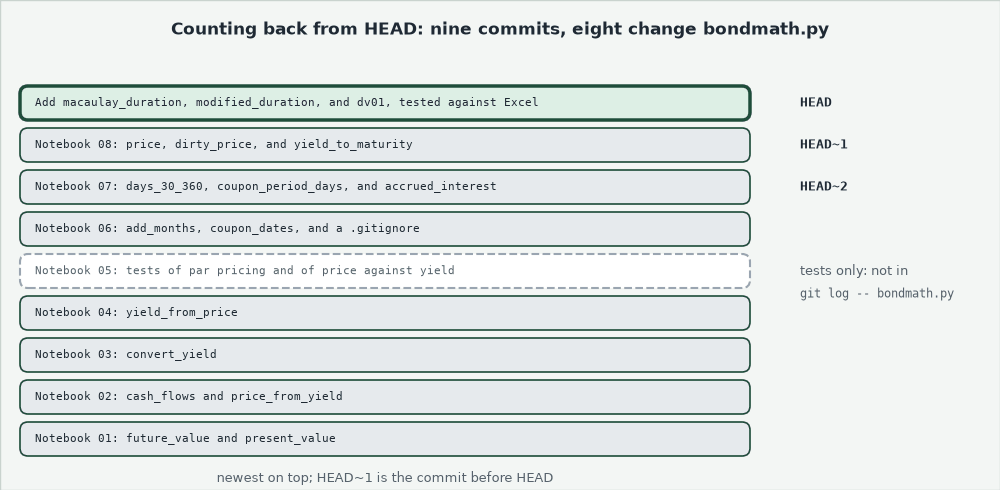

Eight: notebook 05 added tests only.
`HEAD` is the newest commit, `HEAD~1` the one before it, `HEAD~2` two back.

### What the Last Commit Added

In [35]:
# HEAD~1 against HEAD, for bondmath.py only
!git -C "{work}" diff HEAD~1 -- bondmath.py

diff --git a/bondmath.py b/bondmath.py
index aeed858..85425dd 100644
--- a/bondmath.py
+++ b/bondmath.py
@@ -363,3 +363,58 @@ def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean
             high_pct = mid_pct
     # the middle of the final bracket
     return (low_pct + high_pct) / 2
+
+
+def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
+                      basis: str = "30/360") -> float:
+    """Macaulay duration in years: the present-value weighted average time of the cash flows.
+
+    Units: coupon_pct and yield_pct in percent a year; the result is in years.
+    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
+    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
+    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
+    """
+    # the coupon dates and day counts (thes

Every line starts with `+`: today added three functions and changed nothing that was there.

**Git answers "when did this change?" for one file, and `HEAD~1` names the commit before.**

## 9.7 Signs: Long and Short

Price and yield move opposite ways, so say the convention out loud:

* DV01 is the gain on a long position when the yield falls 1 bp; it loses about as much when the yield rises 1 bp.
* For a move of n bp, the change in value is about minus position DV01 times n.
* A short has a negative par held, so a negative DV01: it gains when yields rise.

### The Book, 1 bp Either Way

In [36]:
book_dv01 = bonds['position_dv01'].sum()
for shift_bp in (1, -1):
    # every position repriced at its yield plus the move, in dollars
    change = sum([(bondmath.price(settlement, m, c, y + shift_bp / 100)
                   - bondmath.price(settlement, m, c, y)) * par / 100
                  for m, c, y, par in zip(maturities, coupons, yields, bonds['par_held'])])
    print(f'{shift_bp} bp: estimate {-book_dv01 * shift_bp:,.2f}, repriced {change:,.2f} dollars')

1 bp: estimate -6,154.97, repriced -6,153.13 dollars
-1 bp: estimate 6,154.97, repriced 6,156.81 dollars


For 1 bp the estimate is within 2 dollars of a full reprice; notebook 10 measures that gap.
Every position is long, so the book loses when yields rise: a statement about signs, not a view on yields.

### A Short Position

In [37]:
halvering = bonds.set_index('issuer').loc['Halvering Foods']
# 2,000,000 of Halvering sold short: a negative par held
short_par = -2_000_000
short_dv01_dollars = halvering['dv01'] * short_par / 100
print(f'Short DV01: {short_dv01_dollars:,.2f} dollars per basis point')
print(f'Change for a 1 bp rise: {-short_dv01_dollars:,.2f} dollars')

Short DV01: -1,350.23 dollars per basis point
Change for a 1 bp rise: 1,350.23 dollars


Same formula, opposite sign.
Some systems flip the sign and report the change for a rise: check the convention before adding DV01s from two sources.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The short, one cell</td><td align="left"><code>short_dv01_dollars</code></td><td align="left"><code>=MDURATION(DATE(2026,11,30),DATE(2036,9,30),7.5/100,7.7/100,2,0)*(PRICE(DATE(2026,11,30),DATE(2036,9,30),7.5/100,7.7/100,100,2,0)+100*7.5/100/2*COUPDAYBS(DATE(2026,11,30),DATE(2036,9,30),2,0)/COUPDAYS(DATE(2026,11,30),DATE(2036,9,30),2,0))/10000*-2000000/100</code></td><td align="left">-1350.2293587337144</td></tr>
</table>
<br clear="left">

### Long and Short, 50 bp Either Way

In [38]:
# -50 to +50 bp in steps of 10: range's third number is the step, and it stops before 51
moves_bp = list(range(-50, 51, 10))
price_now = bondmath.price(settlement, halvering['maturity'], 7.5, 7.7)
# the long's change in dollars, fully repriced; the short's is the same with the sign turned
long_change = [(bondmath.price(settlement, halvering['maturity'], 7.5, 7.7 + bp / 100)
                - price_now) * 2_000_000 / 100 for bp in moves_bp]
short_change = [-change for change in long_change]

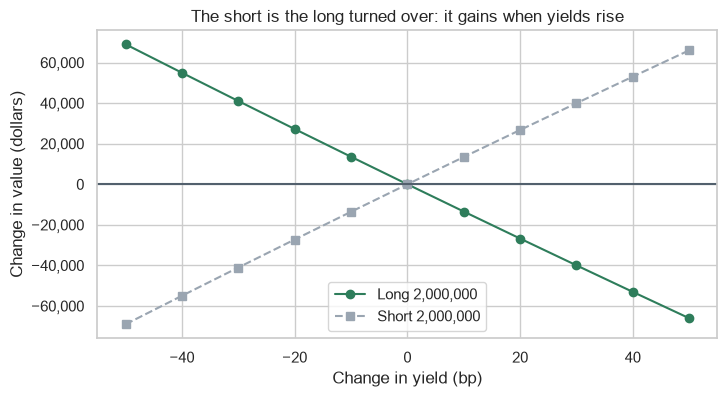

In [39]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(moves_bp, long_change, marker='o', label='Long 2,000,000')
ax.plot(moves_bp, short_change, marker='s', linestyle='--', label='Short 2,000,000')
ax.axhline(0, color='#52606D')
ax.set_title('The short is the long turned over: it gains when yields rise')
ax.set_xlabel('Change in yield (bp)')
ax.set_ylabel('Change in value (dollars)')
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.legend()
plt.show()

**A long gains its DV01 when yields fall 1 bp; a short carries a negative DV01 and gains when they rise.**

## 9.8 Which Duration Is the File's Column?

September's holdings file has a `duration` column, rounded to 3 decimals, for 200 bonds on 30 September.
Its header does not say which duration; Course 1's Series and DataFrames notebook listed it as modified.

**Predict 5**

Q. If the column is modified duration, Macaulay sits above it by modified duration x y / 2; the file's longest is 16.0 years at 5.2 percent. At worst, Macaulay misses the file by:

A) about 0.5 years
B) about 0.05 years
C) about 0.005 years

### Both Durations, All 200 Bonds

In [40]:
holdings = pd.read_csv('holdings.csv')
# bondmath takes dates: .dt.date after pd.to_datetime, as in notebook 08
as_of = pd.to_datetime(holdings['as_of_date']).dt.date
maturity_dates = pd.to_datetime(holdings['maturity']).dt.date
inputs = list(zip(as_of, maturity_dates, holdings['coupon'], holdings['yield_pct']))
holdings['macaulay_python'] = [bondmath.macaulay_duration(*bond) for bond in inputs]
holdings['modified_python'] = [bondmath.modified_duration(*bond) for bond in inputs]

In [41]:
for column in ['macaulay_python', 'modified_python']:
    largest = (holdings[column] - holdings['duration']).abs().max()
    print(f'Largest gap from the file, {column}: {largest:.6f} years')

Largest gap from the file, macaulay_python: 0.456824 years
Largest gap from the file, modified_python: 0.000498 years


A: a shorter bond at a higher yield misses by more than the longest one.
Modified duration stays inside the file's rounding.

### Within Rounding on Every Bond

In [42]:
holdings['gap'] = (holdings['modified_python'] - holdings['duration']).abs()
# the file rounds to 3 decimals: half of 0.001, plus a hair for floating point
assert holdings['gap'].max() <= 0.0005 + 1e-9
same = (holdings['modified_python'].round(3) == holdings['duration']).sum()
print(same, 'of', len(holdings), 'bonds round to the file value')

200 of 200 bonds round to the file value


Unrounded, `test_modified_matches_excel_mduration` already ties all 200 to Excel's `MDURATION`: they are 200 of the reference rows.

### Both Against the File

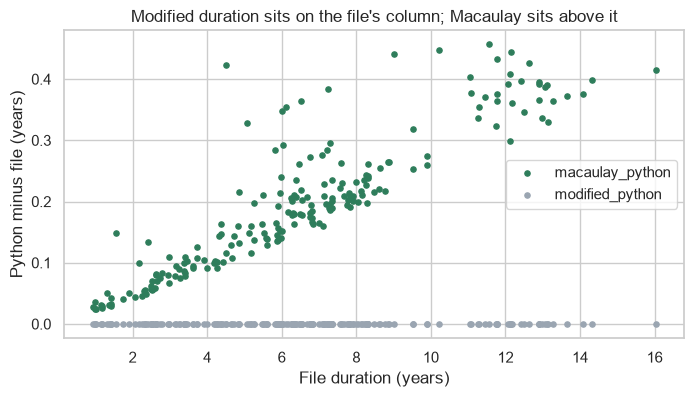

In [43]:
fig, ax = plt.subplots(figsize=(8, 4))
# each Python duration minus the file's: zero means the same number
for column in ['macaulay_python', 'modified_python']:
    ax.scatter(holdings['duration'], holdings[column] - holdings['duration'], s=14, label=column)
ax.set_title("Modified duration sits on the file's column; Macaulay sits above it")
ax.set_xlabel('File duration (years)')
ax.set_ylabel('Python minus file (years)')
ax.legend(loc='center right')
plt.show()

**The file's `duration` column is modified duration, on all 200 bonds.**

## Bring It Home

Copy the work folder's two files into your own `my_bondmath` folder, test them there, and commit.
The copy replaces your files, so anything of your own must be in the work folder first.
In a PowerShell terminal in VS Code, with the course's `.venv` active (use the folder name the setup printed):

```powershell
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$env:TEMP\pfi_course2_09_k4w7q2xr\bondmath.py", "$env:TEMP\pfi_course2_09_k4w7q2xr\test_bondmath.py" .
python -m pytest -q
git diff --stat
git commit -am "Add macaulay_duration, modified_duration, and dv01, tested against Excel"
git log --oneline -- bondmath.py
git diff HEAD~1 -- bondmath.py
```

pytest shows 27 passed, and the log lists every day that changed your module.
A long log or diff opens page by page: space for the next page, `q` to quit.
In Colab, download the two files from the work folder under `/tmp` instead.
The work folder stays in your temp folder; the system clears it in time.

## You Can Now

By the end of this notebook, you can:

* Compute Macaulay duration by hand, as a value-weighted average time, and in a sheet with `SUMPRODUCT`.
* Write a test first and watch it fail before the function exists.
* Compute Macaulay and modified duration with `bondmath`, tied to `DURATION` and `MDURATION`.
* Turn modified duration into DV01 per 100, per position, and for the book, in dollars.
* Check DV01 by bumping the yield 1 bp either way.
* Read the sign of DV01 for a long and a short position.
* Ask Git which commits changed one file, and what the last one added.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The second set of four bonds, settled 30 November at their issue yields, with an invented position in each.
Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: `check`, and the bonds.

In [44]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [45]:
exercise_bonds = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'maturity': [date(2030, 9, 30), date(2028, 9, 30), date(2032, 9, 30), date(2034, 9, 30)],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
    'par_held': [2_500_000, 6_000_000, 3_500_000, 1_500_000],
})
exercise_bonds

,ticker,coupon_pct,maturity,yield_pct,par_held
0,OSTV,5.625,2030-09-30,5.80,2500000
1,TRNW,4.375,2028-09-30,4.30,6000000
2,OSMC,5.000,2032-09-30,5.35,3500000
3,CLDB,8.250,2034-09-30,8.60,1500000


### Exercise 1

Q. Compute the Macaulay and modified duration of the four bonds. Store Osmere's (`OSMC`) modified duration in **ex1_osmere_modified** and the ticker with the longest Macaulay duration in **ex1_longest**.

In [46]:
ex1_osmere_modified = ...
ex1_longest = ...

In [47]:
check('Exercise 1 Osmere modified duration', ex1_osmere_modified, 4.949931473729879)
check('Exercise 1 longest Macaulay duration', ex1_longest, 'CLDB')

Exercise 1 Osmere modified duration: not attempted yet
Exercise 1 longest Macaulay duration: not attempted yet


### Exercise 2

Q. Compute Tarnwick's (`TRNW`) DV01 per 100 two ways: with `bondmath.dv01`, in **ex2_dv01**, and by bumping its yield 1 bp each way with `bondmath.price`, in **ex2_bump**.

In [48]:
ex2_dv01 = ...
ex2_bump = ...

In [49]:
check('Exercise 2 Tarnwick DV01', ex2_dv01, 0.017476340807498596)
check('Exercise 2 Tarnwick bump', ex2_bump, 0.01747634098926909)

Exercise 2 Tarnwick DV01: not attempted yet
Exercise 2 Tarnwick bump: not attempted yet


### Exercise 3

Q. Add `position_dv01_dollars(par, dv01_per_100)` to the module, docstring first (units, the sign of a short, the Excel formula), and `test_position_dv01_dollars_hand_case` with a case worked by hand, the same case short, and Quorvane's 5,000,000 at the reference file's `dv01`. Run pytest, reload, and store the four positions' book DV01 in dollars in **ex3_book**.

In [50]:
%%writefile -a bondmath.py


# Exercise 3: write position_dv01_dollars(par, dv01_per_100) below this line

Appending to bondmath.py


In [51]:
%%writefile -a test_bondmath.py


# Exercise 3: write test_position_dv01_dollars_hand_case() below this line

Appending to test_bondmath.py


In [52]:
# run pytest as in the lesson, reload the module, then call your function
ex3_book = ...

In [53]:
check('Exercise 3 book DV01 in dollars', ex3_book, 4443.097876532716)

Exercise 3 book DV01 in dollars: not attempted yet


### Exercise 4: AI check

You gave an assistant the docstring of `modified_duration` (9.3) as the prompt.
The function below came back, written for this course in the style of an assistant's answer; it runs, and holds one bug.

In [54]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def assistant_modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency=2,
                                basis='30/360'):
    """Modified duration in years: the percent price change for a 100 bp change in yield."""
    macaulay = bondmath.macaulay_duration(settlement, maturity, coupon_pct, yield_pct,
                                          frequency, basis)
    # one plus the yield, as a decimal
    return macaulay / (1 + yield_pct / 100)

Q. Test it on every reference row before you trust it.

In [55]:
# the test file's reference rows and bond_inputs (notebook 07), read as the tests read them
from test_bondmath import REFERENCE, bond_inputs
for row in REFERENCE:
    result = assistant_modified_duration(*bond_inputs(row))
    excel_value = float(row['mduration'])
    message = f"{row['case_id']}: {result:.6f}, MDURATION {excel_value:.6f}"
    assert abs(result - excel_value) < 1e-6, message
print("Every row matches Excel's MDURATION")

AssertionError: 99080CAE8: 4.504161, MDURATION 4.626971

Q. Read the message, find the convention the code broke, and fix the function until the test passes. Store the fixed function's modified duration for Quorvane in **ex4_quorvane**, and for Calderby (8.25 percent, 30 September 2034, at 8.60) in **ex4_calderby**.

In [56]:
ex4_quorvane = ...
ex4_calderby = ...

In [57]:
check('Exercise 4 Quorvane modified duration', ex4_quorvane, 4.180377687066381)
check('Exercise 4 Calderby modified duration', ex4_calderby, 5.581233589541736)

Exercise 4 Quorvane modified duration: not attempted yet
Exercise 4 Calderby modified duration: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Each position per bp</td><td align="left">Quorvane 2,095.13, Dunmarrow 1,655.26, Pellwick 1,054.35, Halvering 1,350.23 dollars</td></tr>
<tr><td align="left">The book</td><td align="left">6,154.97 dollars per bp</td></tr>
<tr><td align="left">Duration and DV01 tied to Excel</td><td align="left"><code>macaulay_duration</code>, <code>modified_duration</code>, <code>dv01</code>, all 306 rows</td></tr>
<tr><td align="left">The file's column</td><td align="left">Modified duration, all 200 bonds within rounding</td></tr>
</table>
<br clear="left">

Be proud: you can say where a risk number comes from, down to each cash flow, and which way its sign points.

Next: Case Study: Convexity and the September Book (notebook 10) measures what the straight line misses.